In [1]:
# -----------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm, skew, spearmanr, qmc
from scipy.optimize import minimize
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
SK_RANDOM_STATE = np.random.RandomState(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# ---------------------------------------------------------------- 
# Figures settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
BLUE, ORANGE, AQUA, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# ---------------------------------------------------------------------------
# 1. DATA
# ---------------------------------------------------------------------------
X = np.load('..\Function_6_Data\Week_13_Data/F6_Week_13_inputs.npy')
y = np.load('..\Function_6_Data\Week_13_Data/F6_Week_13_outputs.npy')
n, d = X.shape
N_INITIAL = 20
W12 = n - 1                         # row 31: the week-12 query (newest reading)
best = int(np.argmax(y))            # row 30: the week-11 query
xb = X[best]
BEST = y[best]
ym, ys = y.mean(), y.std()
print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried); newest x = {np.round(X[W12], 6)}, y = {y[W12]:.6f}")
print(f"Best observed: row {best}, x = {np.round(xb, 6)}, y = {BEST:.6f}; skew of y = {skew(y):.2f}")


n = 32 (20 initial + 12 queried); newest x = [0.43623  0.435096 0.50014  0.736982 0.012893], y = -0.407848
Best observed: row 30, x = [0.441509 0.427941 0.45014  0.758566 0.062893], y = -0.363831; skew of y = -0.28


In [3]:
# ---------------------------------------------------------------- 
# Models
# ----------------------------------------------------------------

def quad_features(Z):
    Z = np.atleast_2d(Z)
    return np.c_[np.ones(len(Z)), Z, Z ** 2]

def kernel(ard):
    return (ConstantKernel(1.0, (1e-2, 1e2)) * Matern(length_scale=np.ones(d) if ard else 1.0, length_scale_bounds=(1e-2, 1e1), nu=2.5)
            + WhiteKernel(1e-2, (1e-5, 1e0)))

class GP:
    """GP on standardised y; predictions in raw y units."""
    def __init__(self, ard, k=None):
        self.ard, self.k = ard, k
    def fit(self, Xt, yt):
        self.m, self.s = yt.mean(), yt.std()
        self.g = GaussianProcessRegressor(kernel=self.k or kernel(self.ard), alpha=1e-10,
                                          optimizer=None if self.k else "fmin_l_bfgs_b",
                                          n_restarts_optimizer=0 if self.k else 20,
                                          random_state=SEED).fit(Xt, (yt - self.m) / self.s)
        return self
    def predict(self, Z):
        mu, sd = self.g.predict(np.atleast_2d(Z), return_std=True)
        return mu * self.s + self.m, sd * self.s
    def refit_fixed(self):
        return GP(self.ard, self.g.kernel_)

class Hybrid:
    """Additive quadratic trend plus a GP on its residuals."""
    def __init__(self, ard, k=None):
        self.ard, self.k = ard, k
    def fit(self, Xt, yt):
        self.c = np.linalg.lstsq(quad_features(Xt), yt, rcond=None)[0]
        self.r = GP(self.ard, self.k).fit(Xt, yt - quad_features(Xt) @ self.c)
        return self
    def predict(self, Z):
        mu, sd = self.r.predict(Z)
        return mu + quad_features(Z) @ self.c, sd
    def refit_fixed(self):
        return Hybrid(self.ard, self.r.g.kernel_)

class Quad:
    def fit(self, Xt, yt):
        self.c = np.linalg.lstsq(quad_features(Xt), yt, rcond=None)[0]
        return self
    def predict(self, Z):
        return quad_features(Z) @ self.c, np.zeros(len(np.atleast_2d(Z)))
    def refit_fixed(self):
        return Quad()

def make_models(Xt, yt):
    return {"GP isotropic": GP(False).fit(Xt, yt), 
            "GP ARD": GP(True).fit(Xt, yt),
            "additive quadratic": Quad().fit(Xt, yt),
            "quadratic + GP isotropic": Hybrid(False).fit(Xt, yt), 
            "quadratic + GP ARD": Hybrid(True).fit(Xt, yt)}

def p1(mdl, Z):
    return float(np.atleast_1d(mdl.predict(Z)[0])[0])

models = make_models(X, y)
NAMES = list(models)
print(f"\nGP ARD kernel: {models['GP ARD'].g.kernel_}")
print(f"GP isotropic kernel: {models['GP isotropic'].g.kernel_}")


GP ARD kernel: 1.4**2 * Matern(length_scale=[0.737, 0.703, 0.951, 1.34, 1.34], nu=2.5) + WhiteKernel(noise_level=0.000235)
GP isotropic kernel: 1.29**2 * Matern(length_scale=0.844, nu=2.5) + WhiteKernel(noise_level=0.000461)



WEEK-12 PREDICTIONS at the newest point (models refitted on the first 31 rows); observed -0.4078
  GP isotropic               predicted -0.3627 +/- 0.0320   error -0.0452   z = -1.41
  GP ARD                     predicted -0.3493 +/- 0.0236   error -0.0585   z = -2.48
  additive quadratic         predicted -0.4124 +/- 0.0000   error +0.0045   z = +nan
  quadratic + GP isotropic   predicted -0.3499 +/- 0.0489   error -0.0580   z = -1.19
  quadratic + GP ARD         predicted -0.3099 +/- 0.0252   error -0.0979   z = -3.89




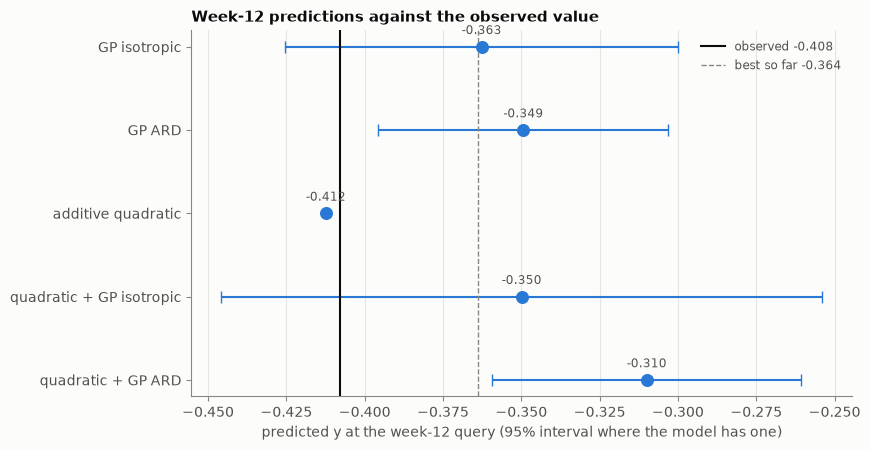

In [4]:
# ---------------------------------------------------------------- 
# Predictions at the newest point
# ---------------------------------------------------------------- 

models_prev = make_models(X[:W12], y[:W12])
prev_pred = {}
print(f"\nWEEK-12 PREDICTIONS at the newest point (models refitted on the first {W12} rows); observed {y[W12]:.4f}")
for name, mdl in models_prev.items():
    m, s = mdl.predict(X[W12])
    prev_pred[name] = (m[0], s[0])
    z = (y[W12] - m[0]) / s[0] if s[0] > 0 else float("nan")
    print(f"  {name:26s} predicted {m[0]:+.4f} +/- {s[0]:.4f}   error {y[W12] - m[0]:+.4f}   z = {z:+.2f}")


print('\n')

# Fig 1: week-12 predictions vs outcome
fig, ax = plt.subplots(figsize=(8.8, 4.6))
vals = [prev_pred[k][0] for k in NAMES]
ypos = np.arange(len(NAMES))[::-1]
ax.scatter(vals, ypos, s=70, color=PAL[0], zorder=3)
for k, (v_, p_) in enumerate(zip(vals, ypos)):
    sd_ = prev_pred[NAMES[k]][1]
    if sd_ > 0:
        ax.errorbar([v_], [p_], xerr=[1.96 * sd_], color=PAL[0], capsize=4, lw=1.5, zorder=2)
    ax.annotate(f"{v_:.3f}", (v_, p_), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5, color=INK2)
ax.axvline(y[W12], color=INK, lw=1.5, label=f"observed {y[W12]:.3f}")
ax.axvline(BEST, color=MUTED, lw=1, ls="--", label=f"best so far {BEST:.3f}")
ax.set_yticks(ypos); ax.set_yticklabels(NAMES)
ax.set_xlabel("predicted y at the week-12 query (95% interval where the model has one)")
ax.set_title("Week-12 predictions against the observed value")
ax.legend(frameon=False, loc="upper right", fontsize=8.5, labelcolor=INK2)
ax.grid(axis="y", visible=False)
fig.tight_layout()


LEAVE-ONE-OUT (hyperparameters fixed at the full fit)
  GP isotropic               RMSE/std=0.456  Spearman=0.907  top-6 RMSE=0.049  95% coverage=0.94  newest point predicted -0.366 (actual -0.408)
  GP ARD                     RMSE/std=0.377  Spearman=0.924  top-6 RMSE=0.029  95% coverage=1.00  newest point predicted -0.365 (actual -0.408)
  additive quadratic         RMSE/std=0.260  Spearman=0.960  top-6 RMSE=0.081  95% coverage=nan  newest point predicted -0.412 (actual -0.408)
  quadratic + GP isotropic   RMSE/std=0.254  Spearman=0.960  top-6 RMSE=0.039  95% coverage=0.78  newest point predicted -0.351 (actual -0.408)
  quadratic + GP ARD         RMSE/std=0.238  Spearman=0.968  top-6 RMSE=0.046  95% coverage=0.81  newest point predicted -0.342 (actual -0.408)




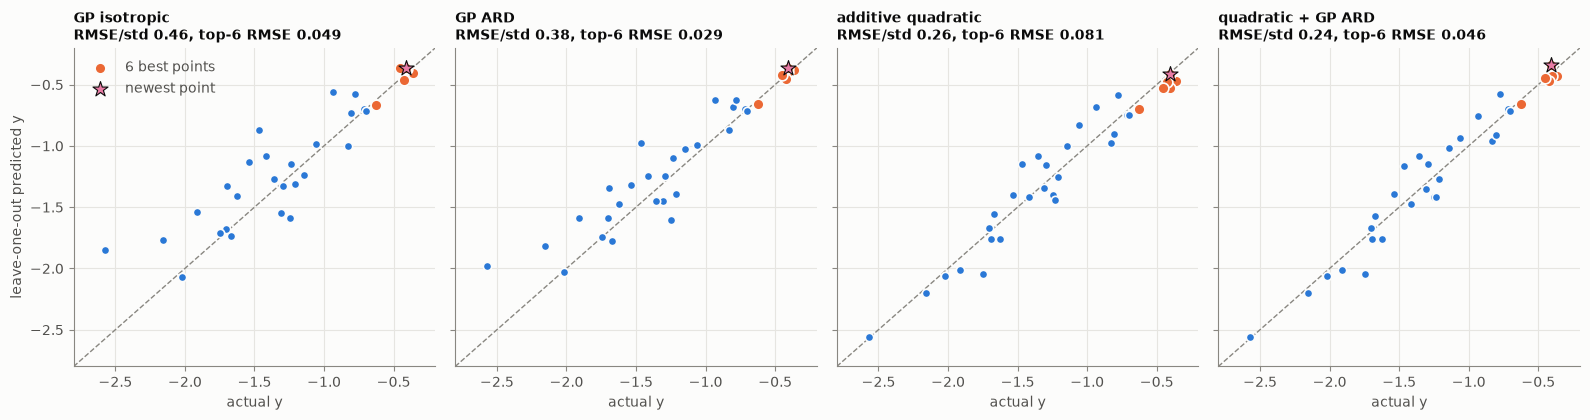

In [5]:
top = np.argsort(-y)[:6]
loos = {}
print("\nLEAVE-ONE-OUT (hyperparameters fixed at the full fit)")
for name, mdl in models.items():
    mu, sd = np.empty(n), np.empty(n)
    for i in range(n):
        keep = np.arange(n) != i
        a, b = mdl.refit_fixed().fit(X[keep], y[keep]).predict(X[i:i + 1])
        mu[i], sd[i] = a[0], b[0]
    loos[name] = (mu, sd)
    cover = np.mean(np.abs((y - mu) / np.maximum(sd, 1e-12)) < 1.96) if name != "additive quadratic" else np.nan
    print(f"  {name:26s} RMSE/std={np.sqrt(np.mean((y - mu) ** 2)) / ys:.3f}  Spearman={spearmanr(y, mu)[0]:.3f}  "
          f"top-6 RMSE={np.sqrt(np.mean((y[top] - mu[top]) ** 2)):.3f}  95% coverage={cover:.2f}  "
          f"newest point predicted {mu[W12]:.3f} (actual {y[W12]:.3f})")

print('\n')
# Fig 2: LOO predicted vs actual for four models
show = ["GP isotropic", "GP ARD", "additive quadratic", "quadratic + GP ARD"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3), sharey=True)
lim = [-2.8, -0.2]
for ax, name in zip(axes, show):
    mu, sd = loos[name]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.scatter(y, mu, s=36, color=PAL[0], edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.scatter(y[top], mu[top], s=60, color=PAL[1], edgecolor=SURFACE, linewidth=1.2, zorder=4, label="6 best points")
    ax.scatter(y[W12], mu[W12], s=130, marker="*", color=PAL[4], edgecolor=INK, linewidth=0.8, zorder=5, label="newest point")
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("actual y")
    ax.set_title(f"{name}\nRMSE/std {np.sqrt(np.mean((y - mu) ** 2)) / ys:.2f}, top-6 RMSE {np.sqrt(np.mean((y[top] - mu[top]) ** 2)):.3f}", fontsize=10)
axes[0].set_ylabel("leave-one-out predicted y")
axes[0].legend(frameon=False, loc="upper left", labelcolor=INK2)
fig.tight_layout()


ADDITIVE QUADRATIC: R2 = 0.974, residual sd 0.089; vertex of each input: [ 0.431  0.402  0.609  0.702 -0.37 ]
  residuals (y minus the quadratic) at the readings nearest the best point:
    row 30  distance 0.000  y = -0.364  quadratic = -0.458  residual = +0.094
    row 31  distance 0.074  y = -0.408  quadratic = -0.412  residual = +0.004
    row 27  distance 0.081  y = -0.405  quadratic = -0.509  residual = +0.104
    row 29  distance 0.137  y = -0.425  quadratic = -0.472  residual = +0.047
    row 26  distance 0.188  y = -0.452  quadratic = -0.518  residual = +0.066
    row 17  distance 0.376  y = -0.936  quadratic = -0.760  residual = -0.176

GRADIENT of each model at the best point (per unit), x1 .. x5
  GP isotropic               [ 0.207 -0.4   -0.145 -0.137  0.008]
  GP ARD                     [ 0.65  -0.356 -0.363  0.181 -0.151]
  additive quadratic         [-0.04  -0.116  0.5   -0.196 -0.483]
  quadratic + GP isotropic   [ 0.021 -0.222 -0.028 -0.095  0.209]
  quadratic + GP A

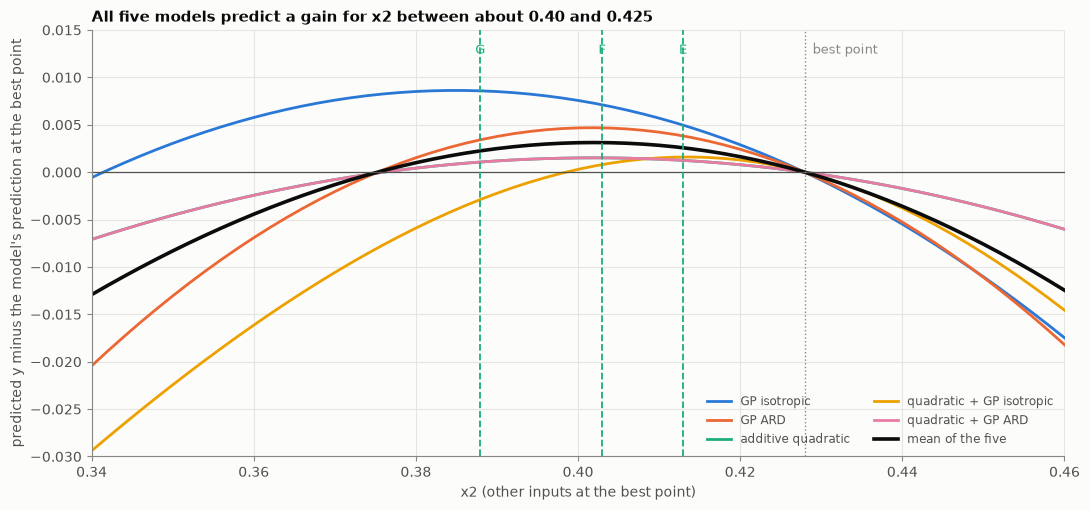

In [6]:
# ---------------------------------------------------------------- 
# Candidates
# ---------------------------------------------------------------- 

# The additive quadratic and its residuals
cq = models["additive quadratic"].c
res_q = y - quad_features(X) @ cq
print(f"\nADDITIVE QUADRATIC: R2 = {1 - res_q @ res_q / np.sum((y - ym) ** 2):.3f}, residual sd {res_q.std():.3f}; "
      f"vertex of each input: {np.round(-cq[1:d + 1] / (2 * cq[d + 1:]), 3)}")
dist = np.linalg.norm(X - xb, axis=1)
print("  residuals (y minus the quadratic) at the readings nearest the best point:")
for i in np.argsort(dist)[:6]:
    print(f"    row {i:2d}  distance {dist[i]:.3f}  y = {y[i]:+.3f}  quadratic = {(quad_features(X[i]) @ cq)[0]:+.3f}  residual = {res_q[i]:+.3f}")

# gradients and single-input scans through the best point
def grad(mdl, h=0.01):
    g = np.zeros(d)
    for j in range(d):
        e = np.zeros(d); e[j] = h
        g[j] = (p1(mdl, xb + e) - p1(mdl, xb - e)) / (2 * h)
    return g
G = {k: grad(m) for k, m in models.items()}
print("\nGRADIENT of each model at the best point (per unit), x1 .. x5")
for k, g in G.items():
    print(f"  {k:26s}", np.round(g, 3))
G_arr = np.array(list(G.values()))
agree = [int(abs(np.sign(G_arr[:, j]).sum())) for j in range(d)]
print(f"  models agreeing on the sign of the gradient, by input: {agree} (of 5)")
base = {k: p1(m, xb) for k, m in models.items()}
def scan(j, values):
    out = []
    for v_ in values:
        x = xb.copy(); x[j] = v_
        out.append([p1(models[k], x) - base[k] for k in NAMES])
    return np.array(out)
xs2 = np.linspace(0.34, 0.46, 61)
sc2 = scan(1, xs2)
print("\nSINGLE-INPUT STEPS of 0.02 from the best point: predicted change by model; models predicting a gain")
for j in range(d):
    for s_ in (+1, -1):
        x = xb.copy(); x[j] = np.clip(x[j] + s_ * 0.02, 0, 1)
        ch = [p1(models[k], x) - base[k] for k in NAMES]
        print(f"  x{j + 1} {'+' if s_ > 0 else '-'}0.02 -> {x[j]:.3f}: " + " ".join(f"{v:+.4f}" for v in ch)
              + f"   mean {np.mean(ch):+.4f}, models with a gain: {sum(v > 0 for v in ch)} of 5")
allpos = [(v_, row) for v_, row in zip(xs2, sc2) if np.all(row > 0)]
print(f"  x2 values at which all five models predict a gain over the best point: {allpos[0][0]:.3f} to {allpos[-1][0]:.3f}; "
      f"mean gain is highest at x2 = {xs2[sc2.mean(1).argmax()]:.3f} (+{sc2.mean(1).max():.4f}); "
      f"the smallest gain across models is highest at x2 = {xs2[sc2.min(1).argmax()]:.3f} (+{sc2.min(1).max():.4f})")



gA = models["GP ARD"]
nv = gA.g.kernel_.k2.noise_level
mu_tr, _ = gA.predict(X)
f_inc = (mu_tr.max() - gA.m) / gA.s
S = qmc.Sobol(d, seed=1).random(2 ** 14)

def ei_ard(Z, xi=0.0):
    m, s = gA.g.predict(np.atleast_2d(Z), return_std=True)
    s = np.sqrt(np.maximum(s ** 2 - nv, 1e-18))
    zz = (m - f_inc - xi) / s
    return (m - f_inc - xi) * norm.cdf(zz) + s * norm.pdf(zz)

def box_argmax(fn, r, centre=None):
    c = xb if centre is None else centre
    lo, hi = np.clip(c - r, 0, 1), np.clip(c + r, 0, 1)
    Z = lo + S * (hi - lo)
    v = fn(Z); x0 = Z[v.argmax()]
    res = minimize(lambda q: -fn(q[None])[0], x0, bounds=list(zip(lo, hi)), method="L-BFGS-B")
    return res.x if -res.fun >= v.max() else x0

ens_gain = lambda Z: np.mean([m.predict(Z)[0] - base[k] for k, m in models.items()], axis=0)
x_quad = np.clip(-cq[1:d + 1] / (2 * cq[d + 1:]), 0, 1)
x_ei_full = box_argmax(lambda Z: ei_ard(Z, 0.01), 1.0)
x_ens = box_argmax(ens_gain, 0.05)
x2_best = float(xs2[sc2.mean(1).argmax()])
def with_x2(v_):
    x = xb.copy(); x[1] = v_
    return x
cands = {
    "A: EI, ARD GP (full domain)": x_ei_full,
    "B: half-step to A": xb + 0.5 * (x_ei_full - xb),
    "C: additive-quadratic peak": x_quad,
    "D: ensemble-mean max (+/-0.05)": x_ens,
    "E: x2 lowered by 0.015": with_x2(xb[1] - 0.015),
    "F: x2 lowered by 0.025 (recommended)": with_x2(round(xb[1] - 0.025, 6)),
    "G: x2 lowered by 0.040": with_x2(xb[1] - 0.040),
}
pred, gains = {}, {}
print("\nCANDIDATES: predicted y by each model; gain = prediction minus the same model's prediction at the best point")
print("  reference: each model at the best observed point: " + "  ".join(f"{k}={v:.3f}" for k, v in base.items()) + f"  (observed {BEST:.4f})")
for name, xc in cands.items():
    pred[name] = {k: p1(m, xc) for k, m in models.items()}
    gains[name] = {k: pred[name][k] - base[k] for k in models}
    print(f"  {name:42s} x = ({', '.join(f'{v:.6f}' for v in xc)})  dist {np.linalg.norm(xc - xb):.3f}")
    print("      predicted: " + "  ".join(f"{k}={v:+.3f}" for k, v in pred[name].items()))
    print("      gain     : " + "  ".join(f"{k}={v:+.4f}" for k, v in gains[name].items())
          + f"   mean gain {np.mean(list(gains[name].values())):+.4f}   models predicting a gain: "
          f"{sum(v > 0 for v in gains[name].values())} of 5")
    print(f"      ARD GP sd at the candidate: {models['GP ARD'].predict(xc)[1][0]:.3f}")
print('\n')
# Fig 4: predicted change along x2 through the best point, every model
fig, ax = plt.subplots(figsize=(11, 5.2))
for k, col in zip(range(len(NAMES)), PAL):
    ax.plot(xs2, sc2[:, k], color=col, lw=2, label=NAMES[k])
ax.plot(xs2, sc2.mean(1), color=INK, lw=2.6, label="mean of the five")
ax.axhline(0, color=INK2, lw=0.9)
ax.axvline(xb[1], color=MUTED, lw=1, ls=":")
ax.text(xb[1] + 0.001, 0.0125, "best point", color=MUTED, fontsize=9)
for name, xc in cands.items():
    if name[0] in "EFG":
        ax.axvline(xc[1], color=PAL[2], lw=1.3, ls="--")
        ax.text(xc[1], 0.0125, name[0], color=PAL[2], fontsize=9, ha="center")
ax.set_xlabel("x2 (other inputs at the best point)"); ax.set_ylabel("predicted y minus the model's prediction at the best point")
ax.set_xlim(0.34, 0.46); ax.set_ylim(-0.03, 0.015)
ax.set_title("All five models predict a gain for x2 between about 0.40 and 0.425")
ax.legend(frameon=False, fontsize=8.5, loc="lower right", labelcolor=INK2, ncol=2)
fig.tight_layout()


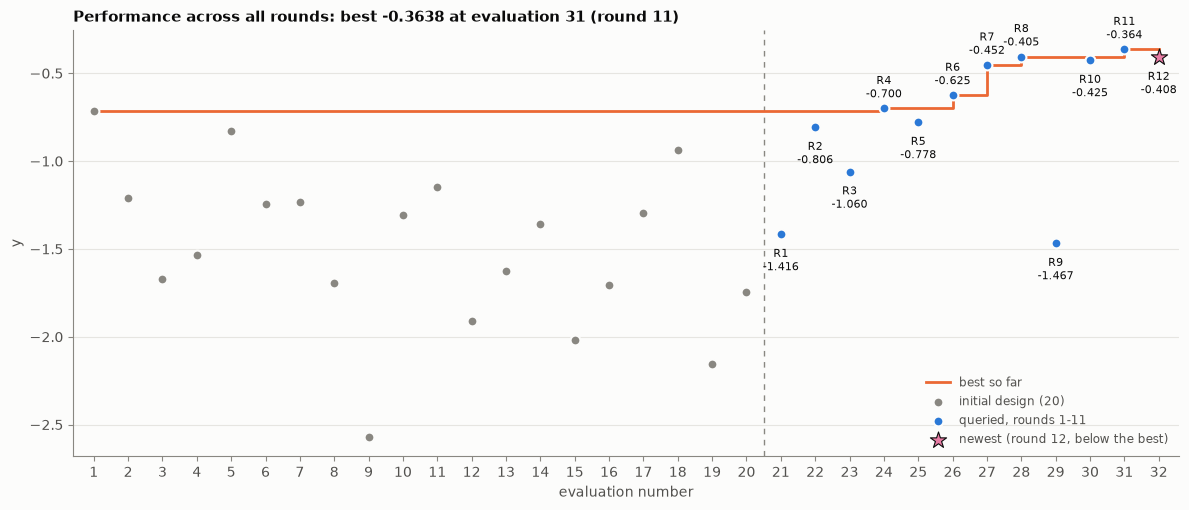

In [7]:
# Fig 3: performance across all rounds
idx = np.arange(1, n + 1)
bsf = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, bsf, where="post", color=PAL[1], lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=50, color=MUTED, edgecolor=SURFACE, linewidth=1.5,
           label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:W12], y[N_INITIAL:W12], s=50, color=PAL[0], edgecolor=SURFACE, linewidth=1.5,
           label=f"queried, rounds 1-{n - N_INITIAL - 1}", zorder=3)
ax.scatter(idx[W12], y[W12], s=150, marker="*", color=PAL[4], edgecolor=INK, linewidth=0.8, zorder=4,
           label=f"newest (round {n - N_INITIAL}, below the best)")
for i in range(N_INITIAL, n):
    ax.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.3f}", (idx[i], y[i]), xytext=(0, 8 if y[i] >= bsf[i] - 1e-12 else -26),
                textcoords="offset points", ha="center", fontsize=8, color=INK)
ax.set_xticks(idx); ax.set_xlim(0.4, n + 0.6); ax.grid(axis="x", visible=False)
ax.set_xlabel("evaluation number"); ax.set_ylabel("y")
ax.set_title(f"Performance across all rounds: best {BEST:.4f} at evaluation {best + 1} (round {best - N_INITIAL + 1})")
ax.legend(frameon=False, loc="lower right", fontsize=8.5, labelcolor=INK2)
fig.tight_layout()